# Mapping income, housing cost, and arrest data in LA County.
## For this part of the project, I am interested in mapping both income and hosuing cost disparities in LA County and spatially relating this to the Million Dollar Hoods data, which shows that South Central and Downtown LA are the two most policed areas in the county. I will be using census data and the LAPD's arrest data to explore the spatial relation between income, housing costs, and arrests. 
### One note on housing costs: for the purposes of this project, I am interested in housing costs as a percentage of median household income in each census tract.

In [2]:
import os
os.chdir('/home/jovyan/221-final-project/Group Assignments/Final maps')

In [3]:
!pip install RISE

### Importing income data for LA County

In [5]:
import pandas as pd

In [6]:
import geopandas as gpd

In [7]:
df = pd.read_csv('/home/jovyan/221-final-project/Group Assignments/Final maps/data/findata/ACSST5Y2023.S2503-Data.csv', low_memory=False)

In [8]:
df.shape

(2499, 555)

In [9]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [10]:
df.sample(5)

,GEO_ID,NAME,S2503_C01_001E,S2503_C01_001M,S2503_C01_002E,S2503_C01_002M,S2503_C01_003E,S2503_C01_003M,S2503_C01_004E,S2503_C01_004M,S2503_C01_005E,S2503_C01_005M,S2503_C01_006E,S2503_C01_006M,S2503_C01_007E,S2503_C01_007M,S2503_C01_008E,S2503_C01_008M,S2503_C01_009E,S2503_C01_009M,S2503_C01_010E,S2503_C01_010M,S2503_C01_011E,S2503_C01_011M,S2503_C01_012E,S2503_C01_012M,S2503_C01_013E,S2503_C01_013M,S2503_C01_014E,S2503_C01_014M,S2503_C01_015E,S2503_C01_015M,S2503_C01_016E,S2503_C01_016M,S2503_C01_017E,S2503_C01_017M,S2503_C01_018E,S2503_C01_018M,S2503_C01_019E,S2503_C01_019M,S2503_C01_020E,S2503_C01_020M,S2503_C01_021E,S2503_C01_021M,S2503_C01_022E,S2503_C01_022M,S2503_C01_023E,S2503_C01_023M,S2503_C01_024E,S2503_C01_024M,S2503_C01_025E,S2503_C01_025M,S2503_C01_026E,S2503_C01_026M,S2503_C01_027E,S2503_C01_027M,S2503_C01_028E,S2503_C01_028M,S2503_C01_029E,S2503_C01_029M,S2503_C01_030E,S2503_C01_030M,S2503_C01_031E,S2503_C01_031M,S2503_C01_032E,S2503_C01_032M,S2503_C01_033E,S2503_C01_033M,S2503_C01_034E,S2503_C01_034M,S2503_C01_035E,S2503_C01_035M,S2503_C01_036E,S2503_C01_036M,S2503_C01_037E,S2503_C01_037M,S2503_C01_038E,S2503_C01_038M,S2503_C01_039E,S2503_C01_039M,S2503_C01_040E,S2503_C01_040M,S2503_C01_041E,S2503_C01_041M,S2503_C01_042E,S2503_C01_042M,S2503_C01_043E,S2503_C01_043M,S2503_C01_044E,S2503_C01_044M,S2503_C01_045E,S2503_C01_045M,S2503_C01_046E,S2503_C01_046M,S2503_C02_001E,S2503_C02_001M,S2503_C02_002E,S2503_C02_002M,S2503_C02_003E,S2503_C02_003M,S2503_C02_004E,S2503_C02_004M,S2503_C02_005E,S2503_C02_005M,S2503_C02_006E,S2503_C02_006M,S2503_C02_007E,S2503_C02_007M,S2503_C02_008E,S2503_C02_008M,S2503_C02_009E,S2503_C02_009M,S2503_C02_010E,S2503_C02_010M,S2503_C02_011E,S2503_C02_011M,S2503_C02_012E,S2503_C02_012M,S2503_C02_013E,S2503_C02_013M,S2503_C02_014E,S2503_C02_014M,S2503_C02_015E,S2503_C02_015M,S2503_C02_016E,S2503_C02_016M,S2503_C02_017E,S2503_C02_017M,S2503_C02_018E,S2503_C02_018M,S2503_C02_019E,S2503_C02_019M,S2503_C02_020E,S2503_C02_020M,S2503_C02_021E,S2503_C02_021M,S2503_C02_022E,S2503_C02_022M,S2503_C02_023E,S2503_C02_023M,S2503_C02_024E,S2503_C02_024M,S2503_C02_025E,S2503_C02_025M,S2503_C02_026E,S2503_C02_026M,S2503_C02_027E,S2503_C02_027M,S2503_C02_028E,S2503_C02_028M,S2503_C02_029E,S2503_C02_029M,S2503_C02_030E,S2503_C02_030M,S2503_C02_031E,S2503_C02_031M,S2503_C02_032E,S2503_C02_032M,S2503_C02_033E,S2503_C02_033M,S2503_C02_034E,S2503_C02_034M,S2503_C02_035E,S2503_C02_035M,S2503_C02_036E,S2503_C02_036M,S2503_C02_037E,S2503_C02_037M,S2503_C02_038E,S2503_C02_038M,S2503_C02_039E,S2503_C02_039M,S2503_C02_040E,S2503_C02_040M,S2503_C02_041E,S2503_C02_041M,S2503_C02_042E,S2503_C02_042M,S2503_C02_043E,S2503_C02_043M,S2503_C02_044E,S2503_C02_044M,S2503_C02_045E,S2503_C02_045M,S2503_C02_046E,S2503_C02_046M,S2503_C03_001E,S2503_C03_001M,S2503_C03_002E,S2503_C03_002M,S2503_C03_003E,S2503_C03_003M,S2503_C03_004E,S2503_C03_004M,S2503_C03_005E,S2503_C03_005M,S2503_C03_006E,S2503_C03_006M,S2503_C03_007E,S2503_C03_007M,S2503_C03_008E,S2503_C03_008M,S2503_C03_009E,S2503_C03_009M,S2503_C03_010E,S2503_C03_010M,S2503_C03_011E,S2503_C03_011M,S2503_C03_012E,S2503_C03_012M,S2503_C03_013E,S2503_C03_013M,S2503_C03_014E,S2503_C03_014M,S2503_C03_015E,S2503_C03_015M,S2503_C03_016E,S2503_C03_016M,S2503_C03_017E,S2503_C03_017M,S2503_C03_018E,S2503_C03_018M,S2503_C03_019E,S2503_C03_019M,S2503_C03_020E,S2503_C03_020M,S2503_C03_021E,S2503_C03_021M,S2503_C03_022E,S2503_C03_022M,S2503_C03_023E,S2503_C03_023M,S2503_C03_024E,S2503_C03_024M,S2503_C03_025E,S2503_C03_025M,S2503_C03_026E,S2503_C03_026M,S2503_C03_027E,S2503_C03_027M,S2503_C03_028E,S2503_C03_028M,S2503_C03_029E,S2503_C03_029M,S2503_C03_030E,S2503_C03_030M,S2503_C03_031E,S2503_C03_031M,S2503_C03_032E,S2503_C03_032M,S2503_C03_033E,S2503_C03_033M,S2503_C03_034E,S2503_C03_034M,S2503_C03_035E,S2503_C03_035M,S2503_C03_036E,S2503_C03_036M,S2503_C03_037E,S2503_C03_037M,S2503_C03_038E,S2503_C03_038M,S2503_C03_039E,S2503_C03_039M,S2503_C03_040E,S2503_C03_040M,S2503_C03_041E,S2503_C03_04

In [11]:
df.GEO_ID.head()

0               Geography
1    1400000US06037101110
2    1400000US06037101122
3    1400000US06037101220
4    1400000US06037101221
Name: GEO_ID, dtype: object

### Extracting FIPS codes

In [12]:
df['FIPS'] = df['GEO_ID'].str[-11:]

In [13]:
print(df[['GEO_ID', 'FIPS']].head())

                 GEO_ID         FIPS
0             Geography    Geography
1  1400000US06037101110  06037101110
2  1400000US06037101122  06037101122
3  1400000US06037101220  06037101220
4  1400000US06037101221  06037101221


### Cleaning and reducing data

In [14]:
df.columns[df.isna().all()].tolist()

['Unnamed: 554']

In [15]:
df = df.dropna(axis=1,how="all")

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2499 entries, 0 to 2498
Columns: 555 entries, GEO_ID to FIPS
dtypes: object(555)
memory usage: 10.6+ MB


In [17]:
columns_to_keep = ['FIPS',
                   'S2503_C01_013E',
                   'S2503_C01_024E',
                   'S2503_C02_013E',
                   'S2503_C02_024E',
                   'S2503_C03_013E',
                   'S2503_C03_024E',
                   'S2503_C04_013E',
                   'S2503_C04_024E',
                   'S2503_C05_013E',
                   'S2503_C05_024E',
                    'S2503_C06_013E',
                   'S2503_C06_024E']
df2 = df[columns_to_keep]

In [18]:
df2.columns= ['FIPS',
'MedHHIncome_All',
'MonthlyCosts_All',
'MedHHIncome_OwnerOccupied',
'MonthlyCosts_OwnerOccupied',
'MedHHIncome_RenterOccupied',
'MonthlyCosts_RenterOccupied',
'MedHHIncome_Mixed',
'MonthlyCosts_Mixed',
'MedHHIncome_NoMortgage',
'MonthlyCosts_NoMortgage',
'MedHHIncome_Mortgage',
'MonthlyCosts_Mortgage']





In [19]:
df2.sample(5)

,FIPS,MedHHIncome_All,MonthlyCosts_All,MedHHIncome_OwnerOccupied,MonthlyCosts_OwnerOccupied,MedHHIncome_RenterOccupied,MonthlyCosts_RenterOccupied,MedHHIncome_Mixed,MonthlyCosts_Mixed,MedHHIncome_NoMortgage,MonthlyCosts_NoMortgage,MedHHIncome_Mortgage,MonthlyCosts_Mortgage
2241,06037700300,100454,2196,100454,2196,109609,2866,109609,2866,94630,1926,94630,1926
649,06037211410,48952,1609,48952,1609,83274,3750,83274,3750,47123,1554,47123,1554
2361,06037910216,112724,2460,112724,2460,116552,2517,116552,2517,56736,2333,56736,2333
1272,06037404100,81602,2079,81602,2079,102465,1886,102465,1886,65573,2186,65573,2186
1221,06037402403,88099,1443,88099,1443,93000,1418,93000,1418,82908,1472,82908,1472


In [20]:
print (df2.dtypes)

FIPS                           object
MedHHIncome_All                object
MonthlyCosts_All               object
MedHHIncome_OwnerOccupied      object
MonthlyCosts_OwnerOccupied     object
MedHHIncome_RenterOccupied     object
MonthlyCosts_RenterOccupied    object
MedHHIncome_Mixed              object
MonthlyCosts_Mixed             object
MedHHIncome_NoMortgage         object
MonthlyCosts_NoMortgage        object
MedHHIncome_Mortgage           object
MonthlyCosts_Mortgage          object
dtype: object


In [21]:
columns_to_convert = ['MedHHIncome_All',
'MonthlyCosts_All',
'MedHHIncome_OwnerOccupied',
'MonthlyCosts_OwnerOccupied',
'MedHHIncome_RenterOccupied',
'MonthlyCosts_RenterOccupied',
'MedHHIncome_Mixed',
'MonthlyCosts_Mixed',
'MedHHIncome_NoMortgage',
'MonthlyCosts_NoMortgage',
'MedHHIncome_Mortgage',
'MonthlyCosts_Mortgage']


In [22]:
# Ensure df2 is an independent copy before modifying
df2 = df2.copy()

# Convert all columns except "FIPS" to numeric
columns_to_convert = [col for col in df2.columns if col != "FIPS"]
df2.loc[:, columns_to_convert] = df2[columns_to_convert].apply(pd.to_numeric, errors="coerce")

In [23]:
df2.dtypes

FIPS                           object
MedHHIncome_All                object
MonthlyCosts_All               object
MedHHIncome_OwnerOccupied      object
MonthlyCosts_OwnerOccupied     object
MedHHIncome_RenterOccupied     object
MonthlyCosts_RenterOccupied    object
MedHHIncome_Mixed              object
MonthlyCosts_Mixed             object
MedHHIncome_NoMortgage         object
MonthlyCosts_NoMortgage        object
MedHHIncome_Mortgage           object
MonthlyCosts_Mortgage          object
dtype: object

### Mapping Income Data

In [24]:
pip install geopandas folium matplotlib

Note: you may need to restart the kernel to use updated packages.


In [25]:
import matplotlib.pyplot as plt

In [26]:
tracts=gpd.read_file('data/Census_Tracts_2020.geojson')
tracts.head()

,OBJECTID,CT20,LABEL,ShapeSTArea,ShapeSTLength,geometry
0,1,101110,1011.10,1.229562e+07,15083.854287,"POLYGON ((-118.28491 34.25948, -118.28492 34.2..."
1,2,101122,1011.22,2.845774e+07,31671.455844,"POLYGON ((-118.29015 34.27417, -118.29015 34.2..."
2,3,101220,1012.20,7.522093e+06,12698.783810,"POLYGON ((-118.281 34.25592, -118.28198 34.255..."
3,4,101221,1012.21,3.812000e+06,9161.710543,"POLYGON ((-118.28735 34.25591, -118.28863 34.2..."
4,5,101222,1012.22,3.191371e+06,9980.600461,"POLYGON ((-118.28594 34.25405, -118.28594 34.2..."


In [27]:
tracts = tracts[['CT20','geometry']]
tracts.head()

,CT20,geometry
0,101110,"POLYGON ((-118.28491 34.25948, -118.28492 34.2..."
1,101122,"POLYGON ((-118.29015 34.27417, -118.29015 34.2..."
2,101220,"POLYGON ((-118.281 34.25592, -118.28198 34.255..."
3,101221,"POLYGON ((-118.28735 34.25591, -118.28863 34.2..."
4,101222,"POLYGON ((-118.28594 34.25405, -118.28594 34.2..."


In [28]:
tracts['FIPS'] ='06' + '037' + tracts['CT20']
tracts.head()

,CT20,geometry,FIPS
0,101110,"POLYGON ((-118.28491 34.25948, -118.28492 34.2...",06037101110
1,101122,"POLYGON ((-118.29015 34.27417, -118.29015 34.2...",06037101122
2,101220,"POLYGON ((-118.281 34.25592, -118.28198 34.255...",06037101220
3,101221,"POLYGON ((-118.28735 34.25591, -118.28863 34.2...",06037101221
4,101222,"POLYGON ((-118.28594 34.25405, -118.28594 34.2...",06037101222


In [29]:
df2 = df2.copy()

In [30]:
# Ensure df2["FIPS"] is a string, removing any unexpected values
df2 = df2[df2["FIPS"].str.isnumeric()]  # Keep only numeric values
df2["FIPS"] = df2["FIPS"].astype(float).astype(int).astype(str).str.zfill(11)

In [31]:
# Ensure tracts["FIPS"] is also a string
tracts["FIPS"] = tracts["FIPS"].astype(str)

In [32]:
# Merge the cleaned df2 with the GeoJSON tracts dataset
tracts_income = tracts.merge(df2, on="FIPS", how="left")

In [33]:
df2.sample(5)

,FIPS,MedHHIncome_All,MonthlyCosts_All,MedHHIncome_OwnerOccupied,MonthlyCosts_OwnerOccupied,MedHHIncome_RenterOccupied,MonthlyCosts_RenterOccupied,MedHHIncome_Mixed,MonthlyCosts_Mixed,MedHHIncome_NoMortgage,MonthlyCosts_NoMortgage,MedHHIncome_Mortgage,MonthlyCosts_Mortgage
427,06037186401,61250.0,1724.0,61250.0,1724.0,67024.0,1583.0,67024.0,1583.0,56927.0,1754.0,56927.0,1754.0
2127,06037603006,76563.0,1609.0,76563.0,1609.0,89427.0,1563.0,89427.0,1563.0,54688.0,1591.0,54688.0,1591.0
1188,06037400602,85369.0,1846.0,85369.0,1846.0,107056.0,1938.0,107056.0,1938.0,67917.0,1721.0,67917.0,1721.0
1587,06037501200,94032.0,2148.0,94032.0,2148.0,111847.0,2445.0,111847.0,2445.0,70163.0,2011.0,70163.0,2011.0
1877,06037552602,112218.0,2016.0,112218.0,2016.0,117500.0,1744.0,117500.0,1744.0,104883.0,2137.0,104883.0,2137.0


In [34]:
tracts.sample(5)

,CT20,geometry,FIPS
1912,554512,"POLYGON ((-118.04635 33.86652, -118.04637 33.8...",06037554512
1001,271902,"POLYGON ((-118.43117 34.00483, -118.42884 34.0...",06037271902
1999,574000,"POLYGON ((-118.10711 33.81882, -118.10734 33.8...",06037574000
1142,302401,"POLYGON ((-118.26798 34.13873, -118.26812 34.1...",06037302401
446,189702,"POLYGON ((-118.33879 34.12051, -118.33904 34.1...",06037189702


In [35]:
tracts_income.sample(5)

,CT20,geometry,FIPS,MedHHIncome_All,MonthlyCosts_All,MedHHIncome_OwnerOccupied,MonthlyCosts_OwnerOccupied,MedHHIncome_RenterOccupied,MonthlyCosts_RenterOccupied,MedHHIncome_Mixed,MonthlyCosts_Mixed,MedHHIncome_NoMortgage,MonthlyCosts_NoMortgage,MedHHIncome_Mortgage,MonthlyCosts_Mortgage
667,212305,"POLYGON ((-118.29895 34.0545, -118.29871 34.05...",06037212305,49400.0,1412.0,49400.0,1412.0,NaN,NaN,NaN,NaN,49175.0,1407.0,49175.0,1407.0
1127,301702,"POLYGON ((-118.26458 34.15321, -118.26458 34.1...",06037301702,81173.0,2161.0,81173.0,2161.0,117000.0,2616.0,117000.0,2616.0,71795.0,2052.0,71795.0,2052.0
766,224320,"POLYGON ((-118.27982 34.04055, -118.27917 34.0...",06037224320,35375.0,1204.0,35375.0,1204.0,NaN,NaN,NaN,NaN,34665.0,1196.0,34665.0,1196.0
775,226420,"POLYGON ((-118.25494 34.01876, -118.25477 34.0...",06037226420,45840.0,1367.0,45840.0,1367.0,92168.0,1684.0,92168.0,1684.0,37188.0,1345.0,37188.0,1345.0
2009,574902,"POLYGON ((-118.13398 33.79626, -118.1342 33.79...",06037574902,85933.0,2384.0,85933.0,2384.0,144583.0,2767.0,144583.0,2767.0,76400.0,2335.0,76400.0,2335.0


### I am interested in plotting monthly housing costs as a percentage of monthly income

In [36]:
#Adding new column: # Avoid division by zero (replace zero or NaN incomes with NaN)
tracts_income["HousingCostPercentage"] = (
    (tracts_income["MonthlyCosts_All"] / (tracts_income["MedHHIncome_All"] / 12)) * 100
)


<Axes: >

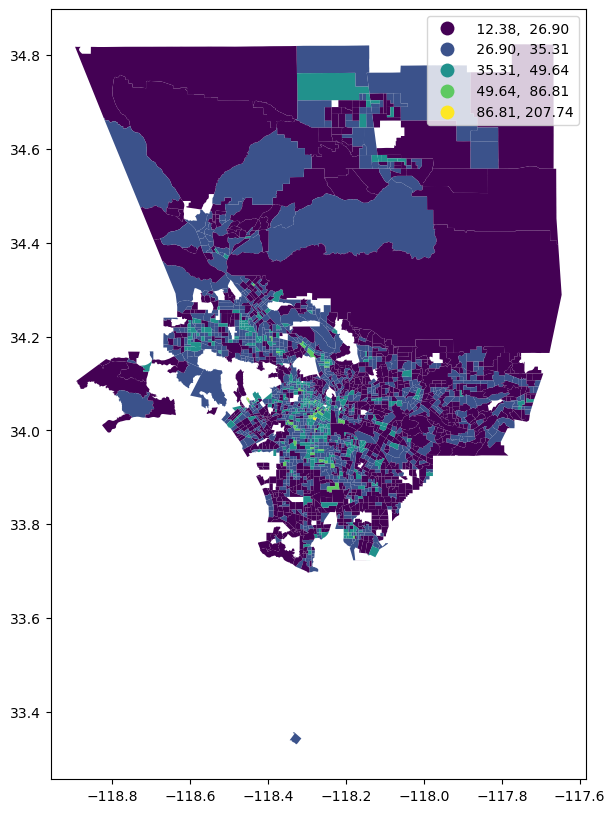

In [37]:
tracts_income.plot(figsize=(12,10),
                 column='HousingCostPercentage',
                 legend=True, 
                 scheme='naturalbreaks')

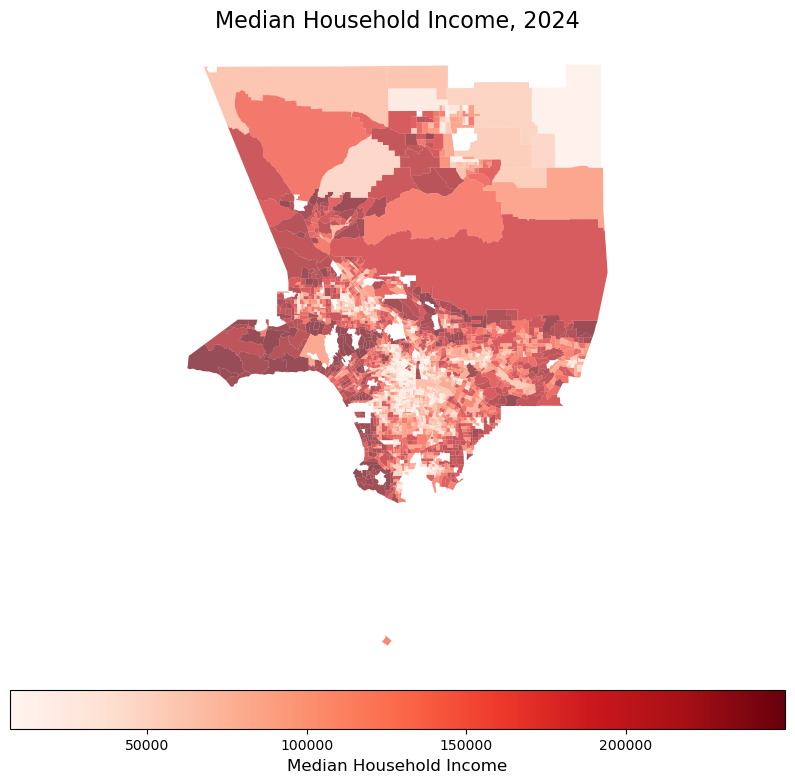

FileNotFoundError: [Errno 2] No such file or directory: '/home/jovyan/221-final-project/Group Assignments/Final maps/221-final-project/Group Assignments/Final maps/medHHincomeLAplot.jpg'

<Figure size 640x480 with 0 Axes>

In [38]:
import matplotlib.pyplot as plt
import geopandas as gpd
import matplotlib as mpl

# Assuming 'tracts_income' is already your GeoDataFrame

# Create the figure and axis with adjusted size
fig, ax = plt.subplots(figsize=(10, 10))

# Plot the data, using the 'MedHHIncome_All' column to set the color
# Use 'Reds' or any other color map you prefer
gdf_plot = tracts_income.plot(
    ax=ax,
    column='MedHHIncome_All',  # Column to be used for coloring
    cmap='Reds',  # Color map for gradient
    legend=False,  # Disable default legend
    alpha=0.7  # Make the polygons slightly transparent for better visibility
)

# Add a colorbar (this acts as the gradient bar)
sm = plt.cm.ScalarMappable(cmap='Reds', norm=plt.Normalize(vmin=tracts_income['MedHHIncome_All'].min(), vmax=tracts_income['MedHHIncome_All'].max()))
sm.set_array([])  # We don't need any data associated with the colorbar
cbar = plt.colorbar(sm, ax=ax, orientation='horizontal', pad=0.02)
cbar.set_label('Median Household Income', fontsize=12)

# Title and styling
ax.set_title('Median Household Income, 2024', fontsize=16)
ax.axis('off')  # Remove axis for better visualization

# Save the plot to a file with adjusted DPI and size
plt.savefig('MedHHIncome.jpg', dpi=150, bbox_inches='tight')

# Show the plot
plt.show()

plt.savefig('221-final-project/Group Assignments/Final maps/medHHincomeLAplot.jpg', dpi=150)

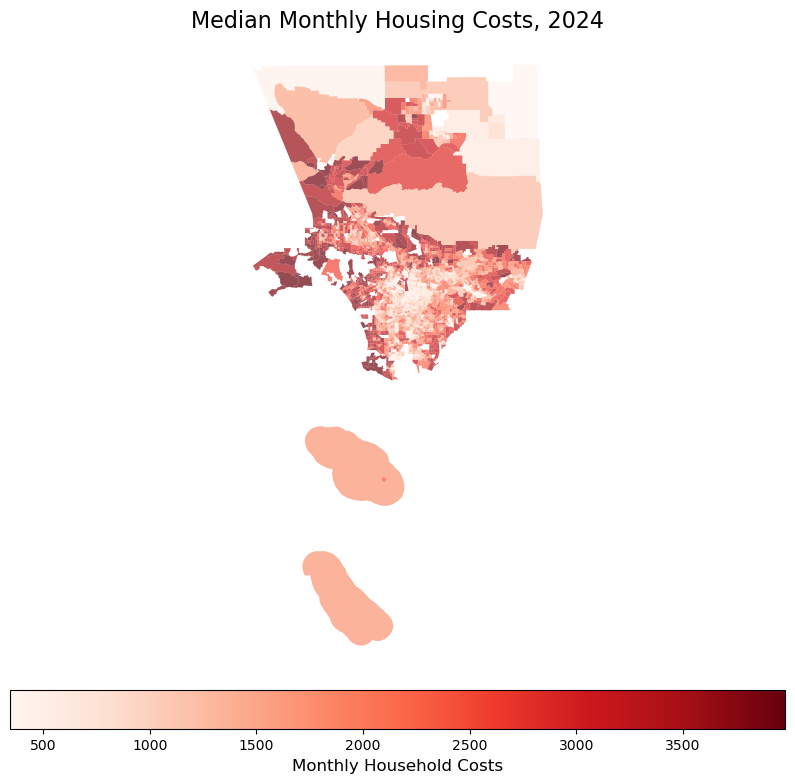

In [39]:
fig, ax = plt.subplots(figsize=(10, 10))

# Plot the data, using the 'MedHHIncome_All' column to set the color
# Use 'Reds' or any other color map you prefer
gdf_plot = tracts_income.plot(
    ax=ax,
    column='MonthlyCosts_All',  # Column to be used for coloring
    cmap='Reds',  # Color map for gradient
    legend=False,  # Disable default legend
    alpha=0.7  # Make the polygons slightly transparent for better visibility
)

# Add a colorbar (this acts as the gradient bar)
sm = plt.cm.ScalarMappable(cmap='Reds', norm=plt.Normalize(vmin=tracts_income['MonthlyCosts_All'].min(), vmax=tracts_income['MonthlyCosts_All'].max()))
sm.set_array([])  # We don't need any data associated with the colorbar
cbar = plt.colorbar(sm, ax=ax, orientation='horizontal', pad=0.02)
cbar.set_label('Monthly Household Costs', fontsize=12)

# Title and styling
ax.set_title('Median Monthly Housing Costs, 2024', fontsize=16)
ax.axis('off')  # Remove axis for better visualization

# Save the plot to a file with adjusted DPI and size
plt.savefig('MedHHCosts.jpg', dpi=150, bbox_inches='tight')

# Show the plot
plt.show()


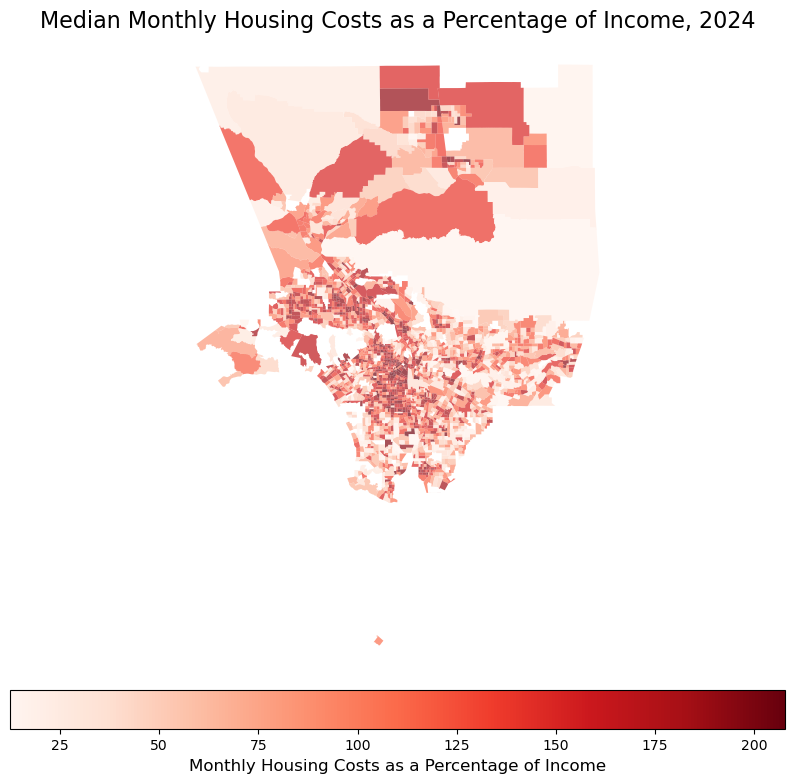

In [40]:
fig, ax = plt.subplots(figsize=(10, 10))

# Plot the data, using the 'MedHHIncome_All' column to set the color
# Use 'Reds' or any other color map you prefer
gdf_plot = tracts_income.plot(
    ax=ax,
    column='HousingCostPercentage',  # Column to be used for coloring
    cmap='Reds',  # Color map for gradient
    legend=False,  # Disable default legend
    alpha=0.7  # Make the polygons slightly transparent for better visibility
)

# Add a colorbar (this acts as the gradient bar)
sm = plt.cm.ScalarMappable(cmap='Reds', norm=plt.Normalize(vmin=tracts_income['HousingCostPercentage'].min(), vmax=tracts_income['HousingCostPercentage'].max()))
sm.set_array([])  # We don't need any data associated with the colorbar
cbar = plt.colorbar(sm, ax=ax, orientation='horizontal', pad=0.02)
cbar.set_label('Monthly Housing Costs as a Percentage of Income', fontsize=12)

# Title and styling
ax.set_title('Median Monthly Housing Costs as a Percentage of Income, 2024', fontsize=16)
ax.axis('off')  # Remove axis for better visualization

# Save the plot to a file with adjusted DPI and size
plt.savefig('MedHHCostsIncome.jpg', dpi=150, bbox_inches='tight')

# Show the plot
plt.show()


In [46]:
import matplotlib.pyplot as plt

# Define bounding boxes for Downtown LA and South Central LA
downtown_bounds = [-118.2673, 34.027, -118.2257, 34.076]  # [min_long, min_lat, max_long, max_lat]
south_central_bounds = [-118.28, 33.9, -118.18, 34.03]  # [min_long, min_lat, max_long, max_lat]

# Function to filter GeoDataFrame based on bounding box
def filter_by_bounding_box(gdf, bounds):
    min_long, min_lat, max_long, max_lat = bounds
    return gdf.cx[min_long:max_long, min_lat:max_lat]

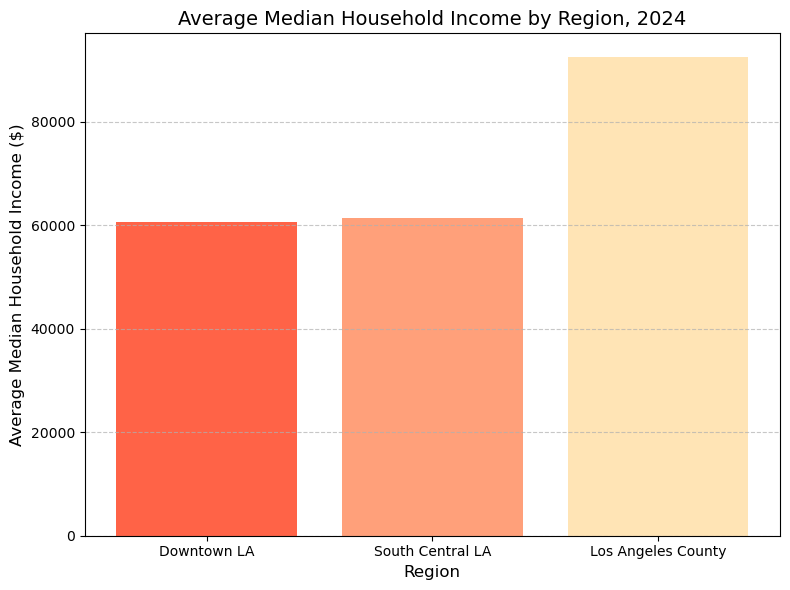

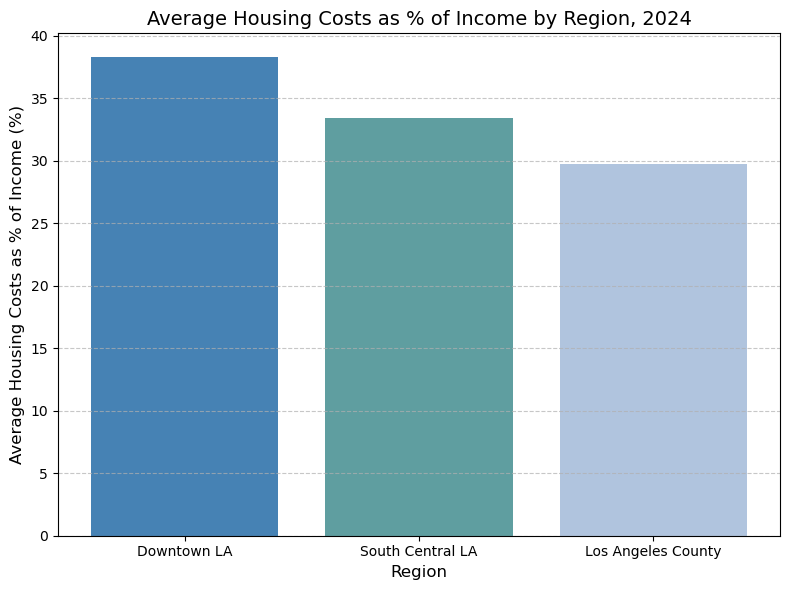

In [47]:
# Function to calculate average values for a specific column within a bounding box
def calculate_average_within_bounds(gdf, column, bounds):
    filtered_gdf = filter_by_bounding_box(gdf, bounds)
    return filtered_gdf[column].mean()

# Calculate averages for each region
average_income_downtown = calculate_average_within_bounds(tracts_income, 'MedHHIncome_All', downtown_bounds)
average_income_south_central = calculate_average_within_bounds(tracts_income, 'MedHHIncome_All', south_central_bounds)
average_income_la_county = tracts_income['MedHHIncome_All'].mean()

average_housing_costs_downtown = calculate_average_within_bounds(tracts_income, 'HousingCostPercentage', downtown_bounds)
average_housing_costs_south_central = calculate_average_within_bounds(tracts_income, 'HousingCostPercentage', south_central_bounds)
average_housing_costs_la_county = tracts_income['HousingCostPercentage'].mean()

# Create dataframes for plotting
income_data = pd.DataFrame({
    "Region": ["Downtown LA", "South Central LA", "Los Angeles County"],
    "Average Median Household Income": [
        average_income_downtown,
        average_income_south_central,
        average_income_la_county
    ]
})

housing_costs_data = pd.DataFrame({
    "Region": ["Downtown LA", "South Central LA", "Los Angeles County"],
    "Average Housing Costs as % of Income": [
        average_housing_costs_downtown,
        average_housing_costs_south_central,
        average_housing_costs_la_county
    ]
})

# Plot Average Median Household Income
plt.figure(figsize=(8, 6))
plt.bar(income_data["Region"], income_data["Average Median Household Income"], color=['#FF6347', '#FFA07A', '#FFE4B5'])
plt.title("Average Median Household Income by Region, 2024", fontsize=14)
plt.ylabel("Average Median Household Income ($)", fontsize=12)
plt.xlabel("Region", fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('/home/jovyan/work/output/average_income_comparison.jpg', dpi=150)
plt.show()

# Plot Average Housing Costs as % of Income
plt.figure(figsize=(8, 6))
plt.bar(housing_costs_data["Region"], housing_costs_data["Average Housing Costs as % of Income"], color=['#4682B4', '#5F9EA0', '#B0C4DE'])
plt.title("Average Housing Costs as % of Income by Region, 2024", fontsize=14)
plt.ylabel("Average Housing Costs as % of Income (%)", fontsize=12)
plt.xlabel("Region", fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('/home/jovyan/work/output/average_housing_costs_comparison.jpg', dpi=150)
plt.show()

### Plotting live arrest data onto our income data maps

In [48]:
client = Socrata("data.lacity.org", None)
results = client.get("amvf-fr72", limit=2000) #get us the API unique identifier, from the URL or API endpoint
arrests = pd.DataFrame.from_records(results) #note that "results" is the variable input for the data
arrests.sample(2)

,rpt_id,report_type,arst_date,time,area,area_desc,rd,age,sex_cd,descent_cd,chrg_grp_cd,grp_description,arst_typ_cd,charge,chrg_desc,dispo_desc,location,lat,lon,location_1,bkg_date,bkg_time,bkg_location,bkg_loc_cd,:@computed_region_qz3q_ghft,:@computed_region_k96s_3jcv,:@computed_region_tatf_ua23,:@computed_region_ur2y_g4cx,:@computed_region_kqwf_mjcx,:@computed_region_2dna_qi2s,crsst
903,6708201,BOOKING,2023-11-05T00:00:00.000,2321,15,N Hollywood,1551,36,M,O,22,Driving Under Influence,M,23152(F)VC,DUI OF ANY DRUG,NaN,LAUREL CANYON,34.1545,-118.3965,"{'type': 'Point', 'coordinates': [-118.3965, 3...",2023-11-06T00:00:00.000,0206,VALLEY - JAIL DIV,4279,8890,345,1336,NaN,5,39,VENTURA FY
426,230401577,RFC,2023-11-08T00:00:00.000,1630,04,Hollenbeck,0497,38,M,W,16,Narcotic Drug Laws,M,11350(A)HS,POSSESSION OF CONTROLLED SUBSTANCE,MISDEMEANOR COMPLAINT FILED,2800 E PICO BL,34.0205,-118.2202,"{'type': 'Point', 'coordinates': [-118.2202, 3...",NaN,NaN,NaN,NaN,23441,530,961,NaN,9,38,NaN


In [49]:
from datetime import datetime
start_date = f"{datetime.now().year}-01-01T00:00:00"
end_date = datetime.now().strftime("%Y-%m-%dT%H:%M:%S")

# Get data from the API with live date range
results = client.get(
    "amvf-fr72", 
    limit=5000, 
    where=f"arst_date between '{start_date}' and '{end_date}'"
)

import pandas as pd
dfa = pd.DataFrame.from_records(results)

# Display the first few rows
print(dfa.head())

    rpt_id report_type                arst_date  time area    area_desc    rd  \
0  6945486     BOOKING  2025-01-01T00:00:00.000  2030   13       Newton  1371   
1  6945475     BOOKING  2025-01-01T00:00:00.000  1825   10  West Valley  1025   
2  6945170     BOOKING  2025-01-01T00:00:00.000  0735   06    Hollywood  0636   
3  6945153     BOOKING  2025-01-01T00:00:00.000  0630   01      Central  0182   
4  6945402     BOOKING  2025-01-01T00:00:00.000  0930   17   Devonshire  1794   

  age sex_cd descent_cd chrg_grp_cd                 grp_description  \
0  30      M          B          12             Weapon (carry/poss)   
1  58      M          H          08                  Other Assaults   
2  38      F          B          22         Driving Under Influence   
3  29      M          B          24  Miscellaneous Other Violations   
4  38      M          W          06                         Larceny   

  arst_typ_cd       charge                                   chrg_desc  \
0           

In [50]:
dfa.sample(5)

,rpt_id,report_type,arst_date,time,area,area_desc,rd,age,sex_cd,descent_cd,chrg_grp_cd,grp_description,arst_typ_cd,charge,chrg_desc,dispo_desc,location,crsst,lat,lon,location_1,bkg_date,bkg_time,bkg_location,bkg_loc_cd
2784,6957851,BOOKING,2025-01-25T00:00:00.000,2225,10,West Valley,1088,37,M,B,04,Aggravated Assault,F,273.5(A)PC,CORPORAL INJURY ON SPOUSE/COHABITANT/ETC,OTHER (REQUIRES ADDITION ACTION),16100 VENTURA BL,NaN,34.1564,-118.4837,"{'type': 'Point', 'coordinates': [-118.4837, 3...",2025-01-26T00:00:00.000,0054,VALLEY - JAIL DIV,4279
4195,6964019,BOOKING,2025-02-06T00:00:00.000,1110,07,Wilshire,0725,29,M,W,06,Larceny,M,459.5(A)PC,SHOPLIFTING,MISDEMEANOR COMPLAINT FILED,BEVERLY,VISTA,34.0762,-118.3522,"{'type': 'Point', 'coordinates': [-118.3522, 3...",2025-02-06T00:00:00.000,1354,METRO - JAIL DIVISION,4273
2873,6957882,BOOKING,2025-01-26T00:00:00.000,0200,11,Northeast,1153,49,M,B,16,Narcotic Drug Laws,F,11377HS,POSS CONTROLLED SUBS W/SP PRIOR,849(B)(1) PC/TECHNICAL ARREST,2100 N HOBART BL,NaN,34.1084,-118.3061,"{'type': 'Point', 'coordinates': [-118.3061, 3...",2025-01-26T00:00:00.000,0524,METRO - JAIL DIVISION,4273
2447,6956610,BOOKING,2025-01-23T00:00:00.000,0830,21,Topanga,2148,41,M,W,16,Narcotic Drug Laws,M,11350(A)HS,POSSESSION OF CONTROLLED SUBSTANCE,MISDEMEANOR COMPLAINT FILED,20100 ARCHWOOD ST,NaN,34.192,-118.571,"{'type': 'Point', 'coordinates': [-118.571, 34...",2025-01-23T00:00:00.000,1226,VALLEY - JAIL DIV,4279
944,6949016,BOOKING,2025-01-08T00:00:00.000,1710,13,Newton,1361,52,M,H,24,Miscellaneous Other Violations,F,451(D)PC,ARSON OF PROPERTY,FELONY COMPLAINT FILED,46TH ST,GRAND ST,34.002,-118.2805,"{'type': 'Point', 'coordinates': [-118.2805, 3...",2025-01-08T00:00:00.000,2025,77TH ST,4212


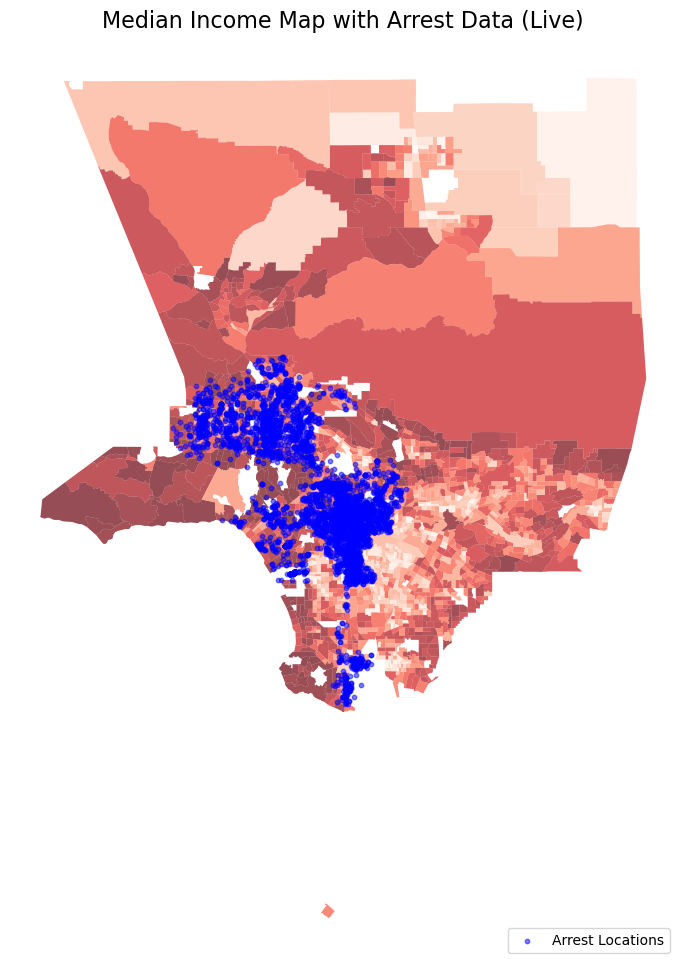

In [55]:
# Step 1: Fetch live arrest data
from shapely.geometry import Point
from sodapy import Socrata
from datetime import datetime

client = Socrata("data.lacity.org", None)  

# Get live arrest data from Jan 1 to now
results = client.get(
    "amvf-fr72",
    limit=5000,
    where=f"arst_date between '{datetime.now().year}-01-01T00:00:00' and '{datetime.now().isoformat()}'"
)

# Convert to DataFrame
arrest_df = pd.DataFrame.from_records(results)

# Step 2: Prepare GeoDataFrame for arrest data
# Ensure latitude and longitude columns exist
arrest_df['latitude'] = arrest_df['lat'].astype(float)
arrest_df['longitude'] = arrest_df['lon'].astype(float)

# Create a GeoDataFrame
geometry = [Point(xy) for xy in zip(arrest_df['lon'], arrest_df['lat'])]
arrest_gdf = gpd.GeoDataFrame(arrest_df, geometry=geometry, crs="EPSG:4326")  # Use WGS84 CRS (common for GPS)

# Reproject to match income data CRS
arrest_gdf = arrest_gdf.to_crs(tracts_income.crs)

# Step 3: Plot income map with arrest data overlay
fig, ax = plt.subplots(figsize=(12, 12))

# Plot median income
tracts_income.plot(
    ax=ax,
    column='MedHHIncome_All',
    cmap='Reds',
    legend=True,
    alpha=0.7
)

# Overlay arrest points
arrest_gdf.plot(
    ax=ax,
    color='blue',
    markersize=10,
    alpha=0.5,
    label="Arrest Locations"
)

# Add labels and legend
ax.set_title('Median Income Map with Arrest Data (Live)', fontsize=16)
ax.legend(loc='lower right', fontsize=10)
ax.axis('off')

# Save and show plot
plt.savefig("income_arrest_map.jpg", dpi=150, bbox_inches='tight')
plt.show()


In [56]:
def isomap():    
    results = client.get(
        "amvf-fr72",
        limit=5000,
        where=f"arst_date between '{datetime.now().year}-01-01T00:00:00' and '{datetime.now().isoformat()}'"
    )
    
    # Convert to DataFrame
    arrest_df = pd.DataFrame.from_records(results)
    
    # Step 2: Prepare GeoDataFrame for arrest data
    # Ensure latitude and longitude columns exist
    arrest_df['latitude'] = arrest_df['lat'].astype(float)
    arrest_df['longitude'] = arrest_df['lon'].astype(float)
    
    # Create a GeoDataFrame
    geometry = [Point(xy) for xy in zip(arrest_df['lon'], arrest_df['lat'])]
    arrest_gdf = gpd.GeoDataFrame(arrest_df, geometry=geometry, crs="EPSG:4326")  # Use WGS84 CRS (common for GPS)
    
    # Reproject to match income data CRS
    arrest_gdf = arrest_gdf.to_crs(tracts_income.crs)
    
    # Step 3: Plot income map with arrest data overlay
    fig, ax = plt.subplots(figsize=(12, 12))
    
    # Plot median income
    tracts_income.plot(
        ax=ax,
        column='HousingCostPercentage',
        cmap='Reds',
        legend=True,
        alpha=0.7
    )
    
    # Overlay arrest points
    arrest_gdf.plot(
        ax=ax,
        color='blue',
        markersize=10,
        alpha=0.5,
        label="Arrest Locations"
    )
    
    # Add labels and legend
    ax.set_title('Housing Costs as a Percentage of Income with Arrest Data (Live)', fontsize=16)
    ax.legend(loc='lower right', fontsize=10)
    ax.axis('off')
    
    # Save and show plot
    plt.savefig("housing_costs_arrest_map.jpg", dpi=150, bbox_inches='tight')
    plt.show()

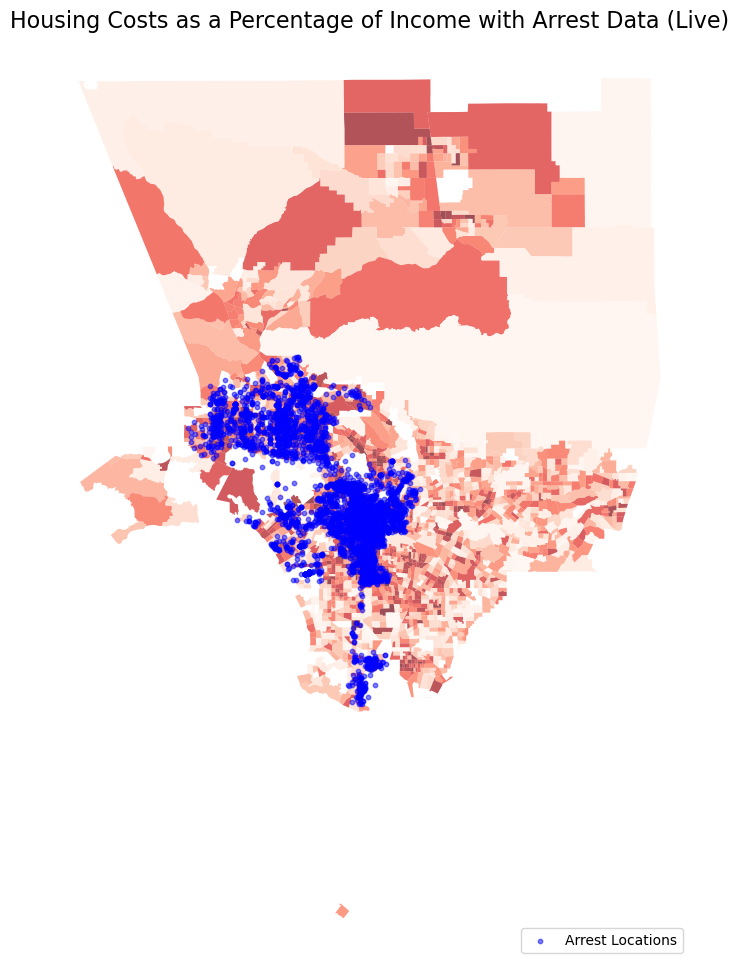

In [57]:
isomap()

Generating map for Downtown LA...


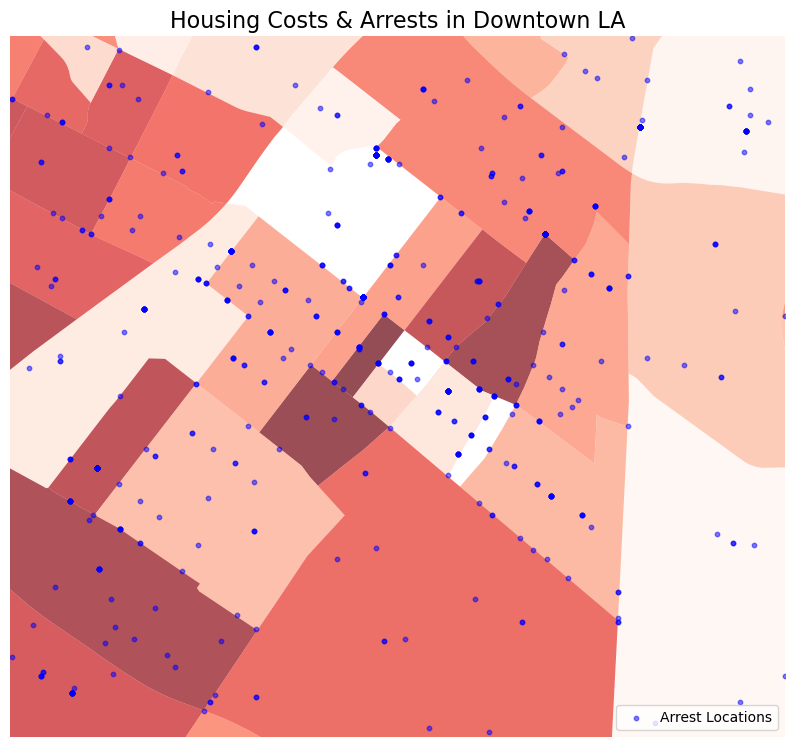

Generating map for South Central LA...


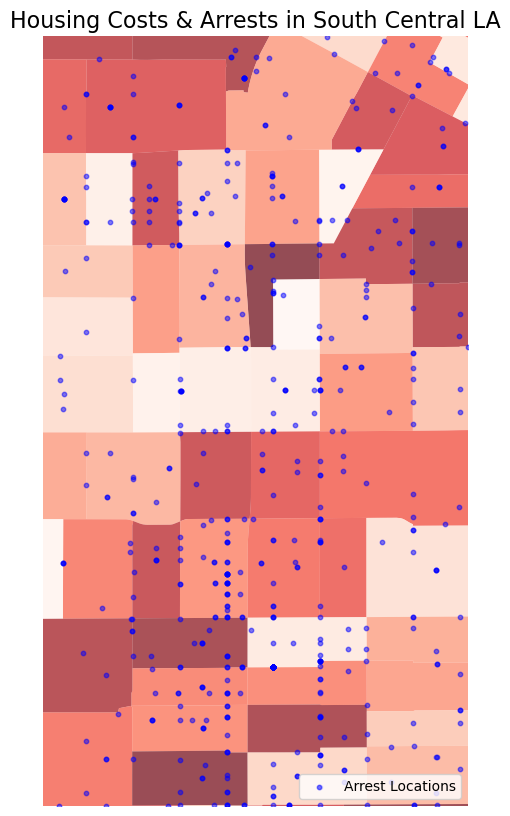

In [59]:
locations = {
    "Downtown LA": {
        "min_lat": 34.03, "max_lat": 34.06,
        "min_lon": -118.27, "max_lon": -118.23
    },
    "South Central LA": {
        "min_lat": 33.96, "max_lat": 34.02,
        "min_lon": -118.30, "max_lon": -118.26
    }
}

def isomap(location_name, min_lat, max_lat, min_lon, max_lon):
    print(f"Generating map for {location_name}...")

    # Step 1: Fetch arrest data within the location and date range
    where_clause = (
        f"arst_date between '{datetime.now().year}-01-01T00:00:00' and '{datetime.now().isoformat()}' "
        f"AND lat BETWEEN {min_lat} AND {max_lat} "
        f"AND lon BETWEEN {min_lon} AND {max_lon}"
    )
    
    results = client.get("amvf-fr72", limit=5000, where=where_clause)
    
    # Convert to DataFrame
    arrest_df = pd.DataFrame.from_records(results)

    # Ensure lat/lon exist
    if 'lat' not in arrest_df or 'lon' not in arrest_df:
        print(f"No data available for {location_name}. Skipping...")
        return
    
    # Convert to float
    arrest_df['latitude'] = arrest_df['lat'].astype(float)
    arrest_df['longitude'] = arrest_df['lon'].astype(float)

    # Create GeoDataFrame
    geometry = [Point(xy) for xy in zip(arrest_df['longitude'], arrest_df['latitude'])]
    arrest_gdf = gpd.GeoDataFrame(arrest_df, geometry=geometry, crs="EPSG:4326")

    # Reproject to match income data CRS
    arrest_gdf = arrest_gdf.to_crs(tracts_income.crs)

    # Step 2: Filter income data to match location
    tracts_income_filtered = tracts_income.cx[min_lon:max_lon, min_lat:max_lat]

    # Step 3: Plot
    fig, ax = plt.subplots(figsize=(10, 10))

    # Plot median income data (only for the given area)
    tracts_income_filtered.plot(ax=ax, column='HousingCostPercentage', cmap='Reds', legend=True, alpha=0.7)

    # Overlay arrests
    arrest_gdf.plot(ax=ax, color='blue', markersize=10, alpha=0.5, label="Arrest Locations")

    # Set zoomed-in view
    ax.set_xlim(min_lon, max_lon)
    ax.set_ylim(min_lat, max_lat)

    # Add labels and legend
    ax.set_title(f'Housing Costs & Arrests in {location_name}', fontsize=16)
    ax.legend(loc='lower right', fontsize=10)
    ax.axis('off')

    # Save and show plot
    plt.savefig(f"{location_name.replace(' ', '_').lower()}_zoomed_map.jpg", dpi=150, bbox_inches='tight')
    plt.show()


# **Loop through locations and generate zoomed-in maps**
for name, bounds in locations.items():
    isomap(name, **bounds)

In [59]:
import math
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point

from geopy.distance import great_circle

def isomap(location_name, center_lat, center_lon, radius_miles):
    print(f"Generating map for {location_name} within {radius_miles} miles...")

    # Convert miles to degrees (approximate conversion)
    lat_buffer = radius_miles / 69  # 1 degree latitude ≈ 69 miles
    lon_buffer = radius_miles / (69 * abs(math.cos(math.radians(center_lat))))  # Adjust for longitude shrinking toward poles

    # Define bounding box
    min_lat, max_lat = center_lat - lat_buffer, center_lat + lat_buffer
    min_lon, max_lon = center_lon - lon_buffer, center_lon + lon_buffer

    # Step 1: Fetch arrest data within the location and date range
    where_clause = (
        f"arst_date between '{datetime.now().year}-01-01T00:00:00' and '{datetime.now().isoformat()}' "
        f"AND lat BETWEEN {min_lat} AND {max_lat} "
        f"AND lon BETWEEN {min_lon} AND {max_lon}"
    )
    
    results = client.get("amvf-fr72", limit=5000, where=where_clause)
    
    # Convert to DataFrame
    arrest_df = pd.DataFrame.from_records(results)

    # Ensure lat/lon exist
    if 'lat' not in arrest_df or 'lon' not in arrest_df:
        print(f"No data available for {location_name}. Skipping...")
        return
    
    # Convert to float
    arrest_df['latitude'] = arrest_df['lat'].astype(float)
    arrest_df['longitude'] = arrest_df['lon'].astype(float)

    # Create GeoDataFrame
    geometry = [Point(xy) for xy in zip(arrest_df['longitude'], arrest_df['latitude'])]
    arrest_gdf = gpd.GeoDataFrame(arrest_df, geometry=geometry, crs="EPSG:4326")

    # Reproject to match income data CRS
    arrest_gdf = arrest_gdf.to_crs(tracts_income.crs)

    # Step 2: Filter income data to match location
    tracts_income_filtered = tracts_income.cx[min_lon:max_lon, min_lat:max_lat]

    # Step 3: Plot
    fig, ax = plt.subplots(figsize=(10, 10))

    # Plot median income data (only for the given area)
    tracts_income_filtered.plot(ax=ax, column='HousingCostPercentage', cmap='Reds', legend=True, alpha=0.7)

    # Overlay arrests
    arrest_gdf.plot(ax=ax, color='blue', markersize=10, alpha=0.5, label="Arrest Locations")

    # Set zoomed-in view
    ax.set_xlim(min_lon, max_lon)
    ax.set_ylim(min_lat, max_lat)

    # Add labels and legend
    ax.set_title(f'Housing Costs & Arrests in {location_name}', fontsize=16)
    ax.legend(loc='lower right', fontsize=10)
    ax.axis('off')

    # Save and show plot
    plt.savefig(f"{location_name.replace(' ', '_').lower()}_{radius_miles}mi_zoomed_map.jpg", dpi=150, bbox_inches='tight')
    plt.show()


Generating map for Downtown LA within 5 miles...


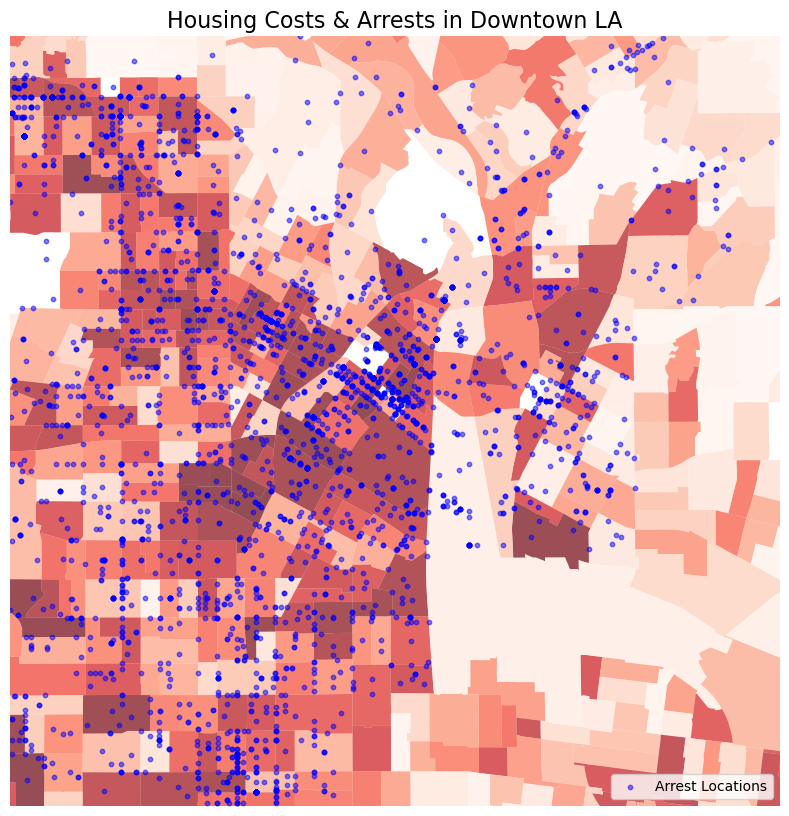

Generating map for South Central LA within 5 miles...


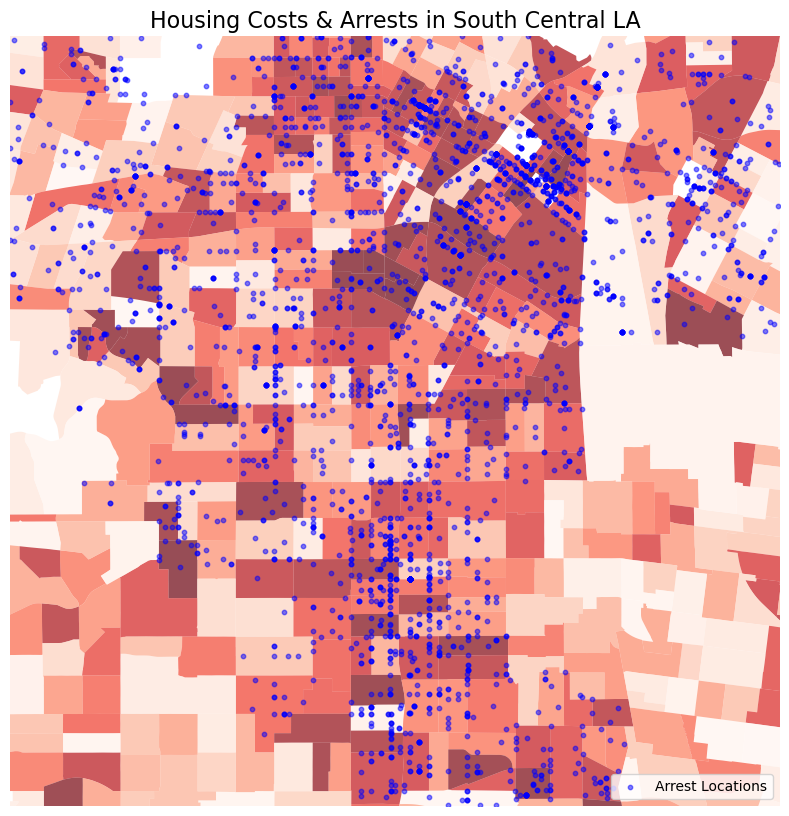

In [60]:
#Downtown: Downtown Los Angeles (DTLA): Latitude: 34.0407 Longitude: -118.2468
#South Central:South Central Los Angeles: Latitude: 34.0006 Longitude: -118.2816
# Define locations with center coordinates and radius
locations = {
    "Downtown LA": {"lat": 34.0407, "lon": -118.2468, "radius": 5},
    "South Central LA": {"lat": 34.0006, "lon": -118.2816, "radius": 5}
}

# Loop through locations and generate maps
for name, info in locations.items():
    isomap(name, info["lat"], info["lon"], info["radius"])

Spearman Correlation: nan (p-value: nan)


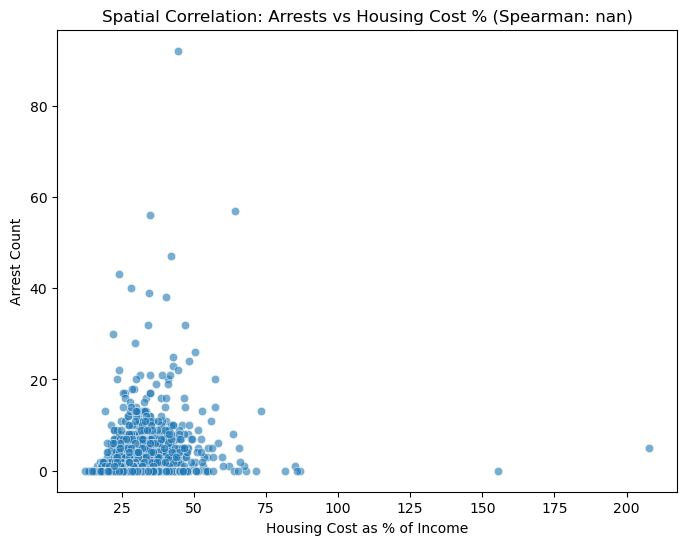

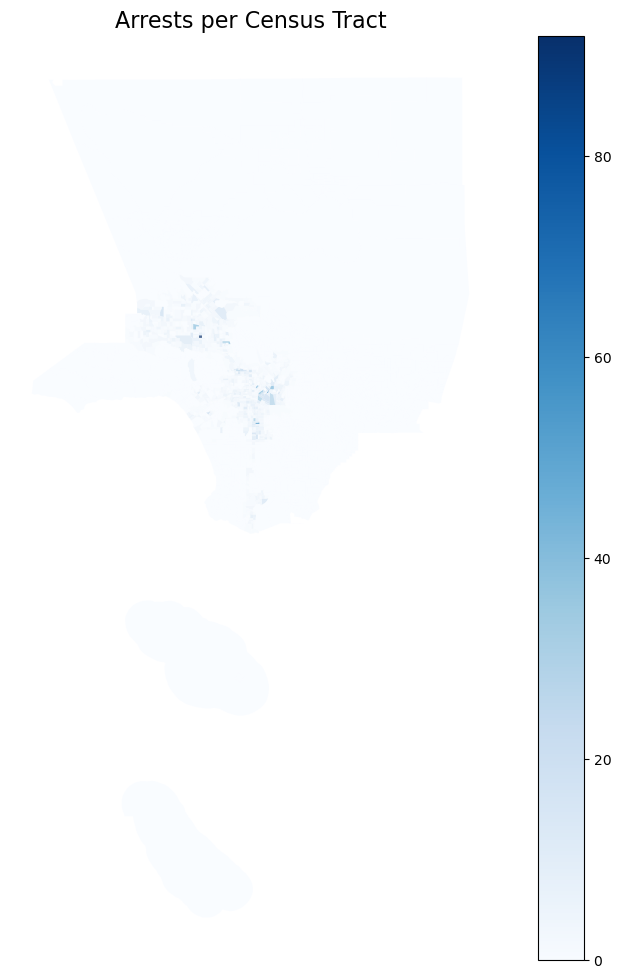

In [60]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from shapely.geometry import Point
from scipy.stats import spearmanr

def spatial_correlation():
    # Get latest arrest data
    results = client.get(
        "amvf-fr72",
        limit=5000,
        where=f"arst_date between '{datetime.now().year}-01-01T00:00:00' and '{datetime.now().isoformat()}'"
    )
    
    # Convert to DataFrame
    arrest_df = pd.DataFrame.from_records(results)

    # Ensure numeric lat/lon
    arrest_df['latitude'] = arrest_df['lat'].astype(float)
    arrest_df['longitude'] = arrest_df['lon'].astype(float)

    # Convert to GeoDataFrame
    geometry = [Point(xy) for xy in zip(arrest_df['lon'], arrest_df['lat'])]
    arrest_gdf = gpd.GeoDataFrame(arrest_df, geometry=geometry, crs="EPSG:4326")
    
    # Reproject to match tracts
    arrest_gdf = arrest_gdf.to_crs(tracts_income.crs)

    # **1. Spatial Join**: Assign each arrest to a census tract
    joined = gpd.sjoin(arrest_gdf, tracts_income, how="left", predicate="within")

    # **2. Count arrests per tract**
    arrest_counts = joined.groupby("HousingCostPercentage").size().reset_index(name="arrest_count")

    # **3. Merge with tracts_income data**
    tracts_income_counts = tracts_income.merge(arrest_counts, on="HousingCostPercentage", how="left")
    tracts_income_counts["arrest_count"] = tracts_income_counts["arrest_count"].fillna(0)  # Fill missing with 0

    # **4. Compute Correlation**
    corr, p_value = spearmanr(
        tracts_income_counts["HousingCostPercentage"], 
        tracts_income_counts["arrest_count"]
    )

    print(f"Spearman Correlation: {corr:.4f} (p-value: {p_value:.4f})")

    # **5. Scatterplot of Housing Cost % vs Arrest Count**
    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        x=tracts_income_counts["HousingCostPercentage"],
        y=tracts_income_counts["arrest_count"],
        alpha=0.6
    )
    plt.xlabel("Housing Cost as % of Income")
    plt.ylabel("Arrest Count")
    plt.title(f"Spatial Correlation: Arrests vs Housing Cost % (Spearman: {corr:.2f})")
    plt.show()
    
    # **6. Choropleth Map of Arrest Density**
    fig, ax = plt.subplots(figsize=(12, 12))
    tracts_income_counts.plot(
        ax=ax, column="arrest_count", cmap="Blues", legend=True, alpha=0.7
    )
    ax.set_title("Arrests per Census Tract", fontsize=16)
    ax.axis('off')
    plt.show()

spatial_correlation()


### Re-visualizing rent burden and exploring spatial correlaiton of rent burden

/opt/conda/lib/python3.11/site-packages/contextily/tile.py:645: UserWarning: The inferred zoom level of 26 is not valid for the current tile provider (valid zooms: 0 - 20).
  warnings.warn(msg)


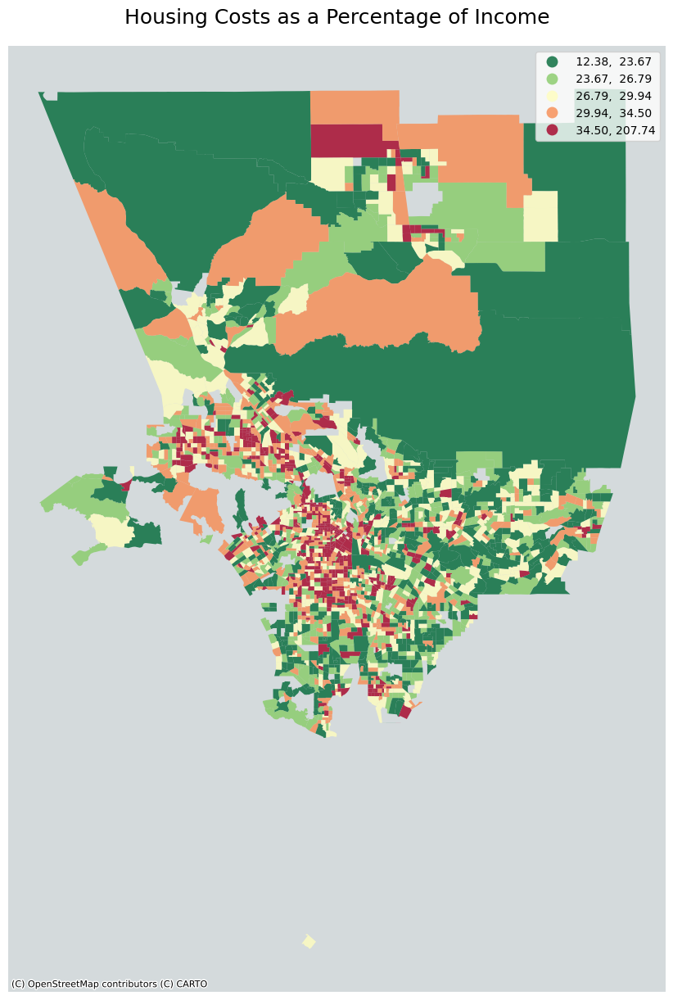

In [61]:
import contextily as ctx
fig,ax = plt.subplots(figsize=(15,15))

tracts_income.plot(ax=ax,
        column='HousingCostPercentage', # this defines the field to "choropleth"
        legend=True,
        alpha=0.8,
        cmap='RdYlGn_r', # the "_r" reverses the color
        scheme='quantiles')

ax.axis('off')
ax.set_title('Housing Costs as a Percentage of Income',fontsize=18,pad=20)
ctx.add_basemap(ax,source=ctx.providers.CartoDB.Positron)

In [65]:
tracts_income.explore(column='HousingCostPercentage', # this defines the field to "choropleth"
        legend=True,
        cmap='RdYlGn_r', # the "_r" reverses the color
        scheme='naturalbreaks',
        tiles='CartoDB positron',
        style_kwds={
            'weight':0.5,
            'color':'black',
            'opacity':0.5
        })

In [70]:
import pandas as pd

# to import data from LA Data portal
from sodapy import Socrata

# to create spatial data
import geopandas as gpd

# for basemaps
import contextily as ctx

# For spatial statistics
import esda
from esda.moran import Moran, Moran_Local

import splot
from splot.esda import moran_scatterplot, plot_moran, lisa_cluster,plot_moran_simulation

import libpysal as lps

# Graphics
import matplotlib.pyplot as plt
import plotly.express as px
# calculate spatial weight
wq =  lps.weights.KNN.from_dataframe(tracts_income,k=8)

# Row-standardization
wq.transform = 'r'

In [72]:
print(tracts_income.dtypes)


CT20                             object
geometry                       geometry
FIPS                             object
MedHHIncome_All                  object
MonthlyCosts_All                 object
MedHHIncome_OwnerOccupied        object
MonthlyCosts_OwnerOccupied       object
MedHHIncome_RenterOccupied       object
MonthlyCosts_RenterOccupied      object
MedHHIncome_Mixed                object
MonthlyCosts_Mixed               object
MedHHIncome_NoMortgage           object
MonthlyCosts_NoMortgage          object
MedHHIncome_Mortgage             object
MonthlyCosts_Mortgage            object
HousingCostPercentage            object
dtype: object


In [73]:
tracts_income["HousingCostPercentage"] = pd.to_numeric(tracts_income["HousingCostPercentage"], errors="coerce")


In [74]:
print(tracts_income.dtypes)

CT20                             object
geometry                       geometry
FIPS                             object
MedHHIncome_All                  object
MonthlyCosts_All                 object
MedHHIncome_OwnerOccupied        object
MonthlyCosts_OwnerOccupied       object
MedHHIncome_RenterOccupied       object
MonthlyCosts_RenterOccupied      object
MedHHIncome_Mixed                object
MonthlyCosts_Mixed               object
MedHHIncome_NoMortgage           object
MonthlyCosts_NoMortgage          object
MedHHIncome_Mortgage             object
MonthlyCosts_Mortgage            object
HousingCostPercentage           float64
dtype: object


In [75]:
y = tracts_income.HousingCostPercentage
moran = Moran(y, wq)
moran.I

np.float64(nan)

In [79]:
tracts_income = tracts_income.dropna(subset=["HousingCostPercentage"])


In [82]:
print(len(y), len(wq.weights))


2380 2495


In [84]:
print(dir(wq))


['_W__get_id_order', '_W__neighbors_0', '_W__set_id_order', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__iter__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', '_build_sparse', '_cache', '_cardinalities', '_component_labels', '_id2i', '_id_order', '_id_order_set', '_n', '_n_components', '_reset', '_s0', '_s1', '_s2', '_s2array', '_sparse', '_transform', 'asymmetries', 'asymmetry', 'cardinalities', 'component_labels', 'data', 'diagW2', 'diagWtW', 'diagWtW_WW', 'from_WSP', 'from_adjlist', 'from_array', 'from_dataframe', 'from_file', 'from_networkx', 'from_shapefile', 'from_sparse', 'full', 'get_transform', 'histogram', 'id2i', 'id_order', 'id_order_set', 'islands', 'k', 'kdtree', 'max_neighbors', 'mean_nei

In [85]:
tracts_in_wq = set(wq.neighbors.keys())  # Tracts in wq
tracts_in_y = set(y.index)  # Tracts in y

missing_in_y = tracts_in_wq - tracts_in_y  # In wq but not in y
missing_in_wq = tracts_in_y - tracts_in_wq  # In y but not in wq

print("Tracts in wq but missing in y:", missing_in_y)
print("Tracts in y but missing in wq:", missing_in_wq)


Tracts in wq but missing in y: {1028, 2058, 2060, 1043, 569, 58, 69, 589, 85, 598, 1113, 602, 94, 1637, 2156, 1651, 117, 2168, 2170, 2171, 639, 1177, 2221, 2222, 2223, 2224, 2226, 2232, 2236, 2480, 2244, 1221, 2245, 2251, 2285, 2286, 2289, 2292, 2298, 2299, 2301, 2304, 2334, 309, 342, 350, 357, 358, 359, 360, 361, 1385, 371, 372, 373, 387, 389, 2437, 2439, 911, 913, 914, 915, 917, 919, 920, 921, 922, 923, 2459, 925, 926, 927, 2460, 2461, 2462, 2463, 2464, 2465, 2466, 935, 2467, 2468, 938, 2469, 2470, 2471, 2472, 943, 944, 2475, 2476, 2478, 2479, 1461, 1462, 1463, 1464, 1973, 2481, 2484, 2485, 2486, 2487, 2488, 2489, 2492, 2493, 2494, 968, 461, 973, 1503, 503, 504}
Tracts in y but missing in wq: set()


In [87]:
print(type(next(iter(y.index))))  # Check first element type in y.index
print(type(next(iter(wq.neighbors.keys()))))  # Check first element type in wq


<class 'int'>
<class 'int'>


In [88]:
from libpysal.weights import W

# Create a new weights matrix only with tracts in y
filtered_neighbors = {k: [n for n in v if n in y.index] for k, v in wq.neighbors.items() if k in y.index}
filtered_wq = W(filtered_neighbors)


In [104]:
print(len(y), len(filtered_wq.neighbors))  # Should be equal


2380 2380


In [105]:
moran = Moran(y, filtered_wq)
print(moran.I)


0.35526916132307484


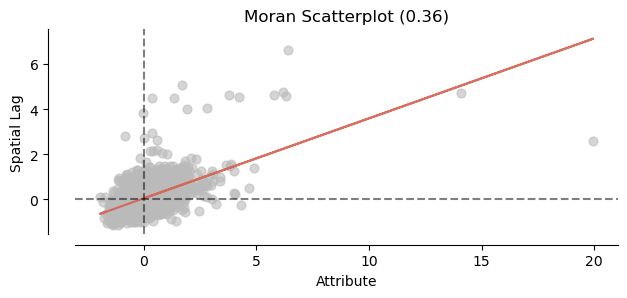

In [106]:
fig, ax = moran_scatterplot(moran, aspect_equal=True)
plt.show()

(<Figure size 700x700 with 1 Axes>,
 <Axes: title={'center': 'Reference Distribution'}, xlabel='Moran I: 0.36', ylabel='Density'>)

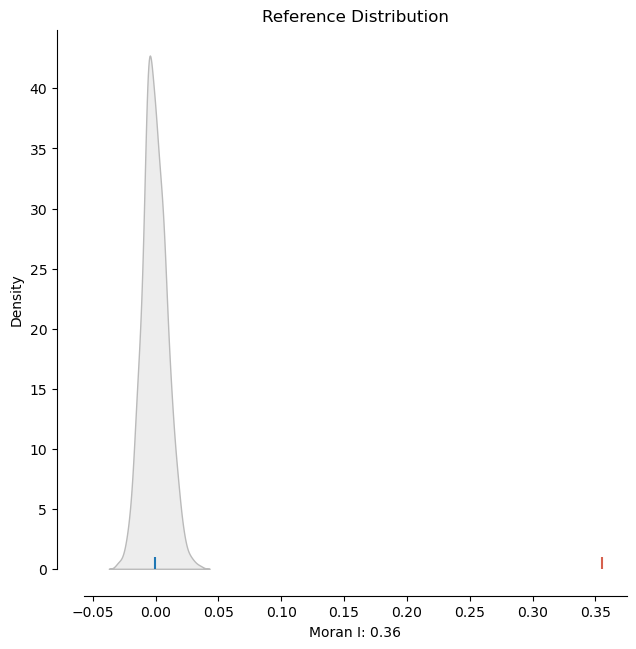

In [107]:
plot_moran_simulation(moran,aspect_equal=False)

In [108]:
moran.p_sim

np.float64(0.001)

In [109]:
lisa = esda.moran.Moran_Local(y, filtered_wq)

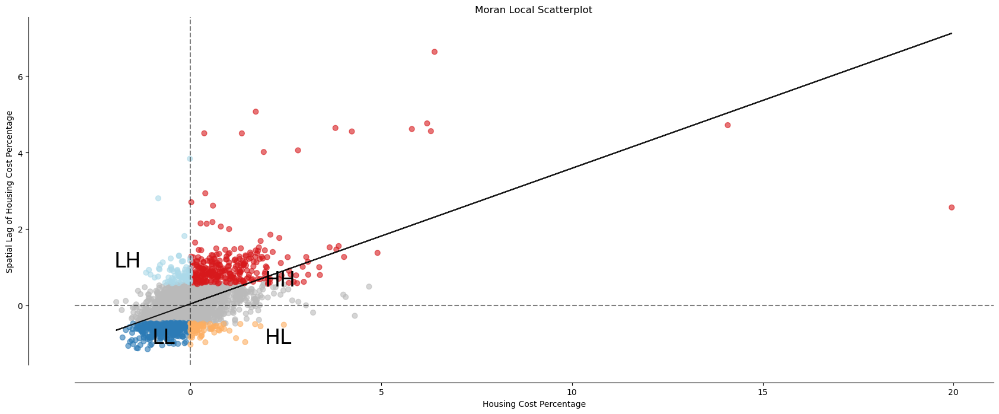

In [110]:
fig,ax = plt.subplots(figsize=(20,15))

moran_scatterplot(lisa, ax=ax, p=0.05)
ax.set_xlabel("Housing Cost Percentage")
ax.set_ylabel('Spatial Lag of Housing Cost Percentage')

# add some labels
plt.text(1.95, 0.5, "HH", fontsize=25)
plt.text(1.95, -1, "HL", fontsize=25)
plt.text(-2, 1, "LH", fontsize=25)
plt.text(-1, -1, "LL", fontsize=25)
plt.show()

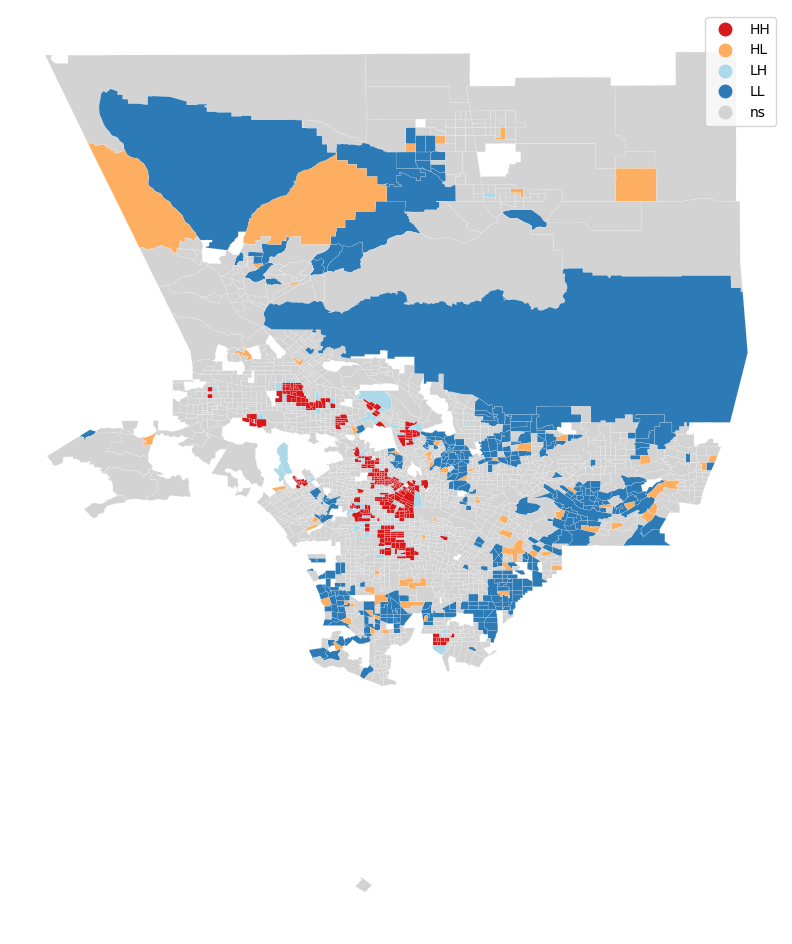

In [111]:
fig, ax = plt.subplots(figsize=(14,12))
lisa_cluster(lisa, tracts_income, p=0.05, ax=ax)
plt.show()

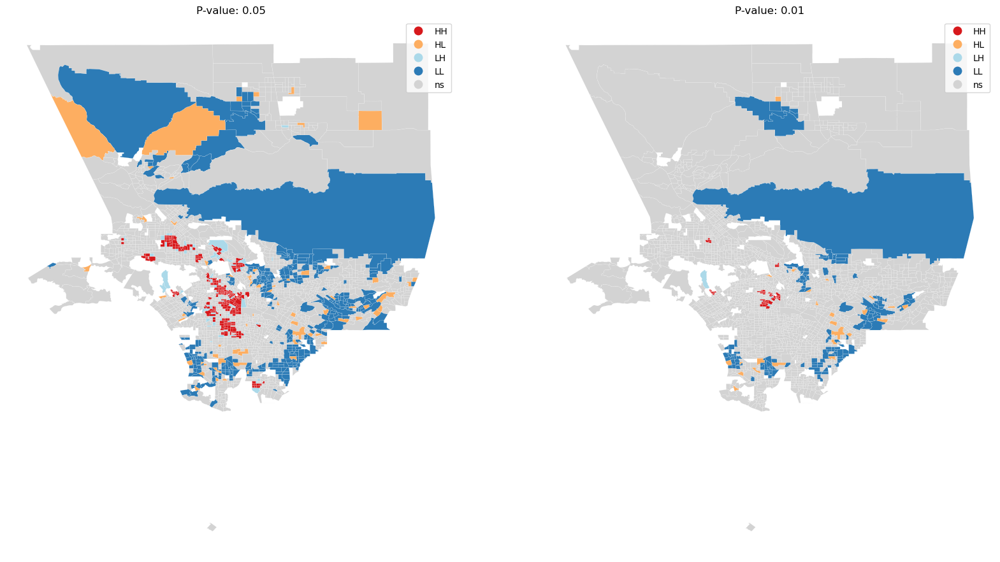

In [112]:
fig, ax = plt.subplots(1, 2, figsize=(20, 12))

# regular count map on the left
lisa_cluster(lisa, tracts_income, p=0.05, ax=ax[0])

ax[0].axis("off")
ax[0].set_title("P-value: 0.05")

# spatial lag map on the right
lisa_cluster(lisa, tracts_income, p=0.01, ax=ax[1])
ax[1].axis("off")
ax[1].set_title("P-value: 0.01")

plt.show()